# Corte de varilla

Una varilla de longitud $n$ se puede cortar en trozos de longitud entera, y un trozo de longitud $i$ se vende por $p_i$. Hay que decidir los cortes que maximizan el ingreso. Si el primer trozo mide $i$, lo que queda es el mismo problema con longitud $n - i$:

$$R[0] = 0, \qquad R[n] = \max_{1 \le i \le n} \left( p_i + R[n - i] \right)$$

Probar todas las formas de cortar cuesta $O(2^{n-1})$; con la tabla $R$ cuesta $O(n^2)$.

## 1. Recursión ingenua frente a memoización

Escribir la recurrencia como función recursiva directa y con `functools.cache`, contando las llamadas que hace cada una para varias longitudes. Usar los precios $p = (1, 5, 8, 9, 10, 17, 17, 20, 24, 30)$ para los trozos de 1 a 10.

In [1]:
from functools import cache

precios = [0, 1, 5, 8, 9, 10, 17, 17, 20, 24, 30]

def corte_ingenuo(n, precios, contador):
    contador[0] += 1
    if n == 0:
        return 0
    return max(precios[i] + corte_ingenuo(n - i, precios, contador) for i in range(1, n + 1))

def corte_memo(n, precios):
    llamadas = 0
    @cache
    def R(m):
        nonlocal llamadas
        llamadas += 1
        return 0 if m == 0 else max(precios[i] + R(m - i) for i in range(1, m + 1))
    return R(n), llamadas

for n in (4, 7, 10):
    contador = [0]
    valor = corte_ingenuo(n, precios, contador)
    assert contador[0] == 2 ** n and (valor, n + 1) == corte_memo(n, precios)
    print(f"n = {n:2}: ingreso {valor:2}, ingenua {contador[0]:5} llamadas, memoizada {n + 1} llamadas")

n =  4: ingreso 10, ingenua    16 llamadas, memoizada 5 llamadas
n =  7: ingreso 18, ingenua   128 llamadas, memoizada 8 llamadas
n = 10: ingreso 30, ingenua  1024 llamadas, memoizada 11 llamadas


## 2. Tabla con reconstrucción de los cortes

Rellenar $R$ de abajo arriba guardando en `primero[m]` la longitud del primer trozo de la mejor solución para $m$, y reconstruir la lista de trozos de cada longitud de 1 a 10.

In [2]:
def corte_varilla(n, precios):
    R, primero = [0] * (n + 1), [0] * (n + 1)
    for m in range(1, n + 1):
        for i in range(1, min(m, len(precios) - 1) + 1):
            if precios[i] + R[m - i] > R[m]:
                R[m], primero[m] = precios[i] + R[m - i], i
    trozos = []
    while n > 0:
        trozos.append(primero[n])
        n -= primero[n]
    return R[-1], trozos

for n in range(1, 11):
    valor, trozos = corte_varilla(n, precios)
    assert valor == sum(precios[t] for t in trozos) and sum(trozos) == n
    print(f"n = {n:2}: {valor:2} con trozos {trozos}")

n =  1:  1 con trozos [1]
n =  2:  5 con trozos [2]
n =  3:  8 con trozos [3]
n =  4: 10 con trozos [2, 2]
n =  5: 13 con trozos [2, 3]
n =  6: 17 con trozos [6]
n =  7: 18 con trozos [1, 6]
n =  8: 22 con trozos [2, 6]
n =  9: 25 con trozos [3, 6]
n = 10: 30 con trozos [10]


## 3. Comprobación contra fuerza bruta

Una varilla de longitud $n$ tiene $n - 1$ puntos donde se puede cortar o no, así que hay $2^{n-1}$ formas de cortarla. Recorrerlas todas con `itertools.product` para precios aleatorios y comprobar que la tabla da el mismo ingreso máximo.

In [3]:
import random
from itertools import product

def trozos_de(n, cortes):
    trozos, inicio = [], 0
    for pos, cortar in enumerate(cortes, 1):
        if cortar:
            trozos.append(pos - inicio)
            inicio = pos
    return trozos + [n - inicio]

def corte_fuerza_bruta(n, precios):
    return max(sum(precios[t] for t in trozos_de(n, cortes)) for cortes in product((False, True), repeat=n - 1))

random.seed(1)
for _ in range(300):
    n = random.randint(1, 12)
    p = [0] + [random.randint(1, 30) for _ in range(n)]
    assert corte_varilla(n, p)[0] == corte_fuerza_bruta(n, p)
print(corte_fuerza_bruta(10, precios), corte_varilla(10, precios)[0])

30 30


## 4. Cortes con coste

Si cada corte cuesta $c$, ya no compensa trocear tanto. Adaptar la recurrencia, $R[m] = \max\left(p_m,\ \max_{1 \le i < m} (p_i + R[m - i] - c)\right)$, y comprobarla contra fuerza bruta. Ver cómo cambia la solución para $n = 8$ y $n = 9$ al subir el coste.

In [4]:
def corte_con_coste(n, precios, coste):
    R, primero = [0] * (n + 1), [0] * (n + 1)
    for m in range(1, n + 1):
        R[m], primero[m] = precios[m], m
        for i in range(1, m):
            if precios[i] + R[m - i] - coste > R[m]:
                R[m], primero[m] = precios[i] + R[m - i] - coste, i
    trozos = []
    while n > 0:
        trozos.append(primero[n])
        n -= primero[n]
    return R[-1], trozos

def coste_fuerza_bruta(n, precios, coste):
    return max(sum(precios[t] for t in trozos) - coste * (len(trozos) - 1)
               for trozos in (trozos_de(n, c) for c in product((False, True), repeat=n - 1)))

random.seed(2)
for _ in range(300):
    n = random.randint(1, 11)
    p = [0] + [random.randint(1, 30) for _ in range(n)]
    coste = random.randint(0, 5)
    assert corte_con_coste(n, p, coste)[0] == coste_fuerza_bruta(n, p, coste)

for n in (8, 9):
    print(f"n = {n}:", ", ".join(f"coste {c} -> {corte_con_coste(n, precios, c)}" for c in range(4)))

n = 8: coste 0 -> (22, [2, 6]), coste 1 -> (21, [2, 6]), coste 2 -> (20, [8]), coste 3 -> (20, [8])
n = 9: coste 0 -> (25, [3, 6]), coste 1 -> (24, [9]), coste 2 -> (24, [9]), coste 3 -> (24, [9])


## 5. Dibujar los cortes óptimos

Con los precios anteriores ampliados con $p_{11} = 31$ y $p_{12} = 33$, dibujar con `matplotlib` una barra horizontal por cada longitud $n$ de 1 a 12, partida en los trozos de la solución óptima y con el ingreso al lado.

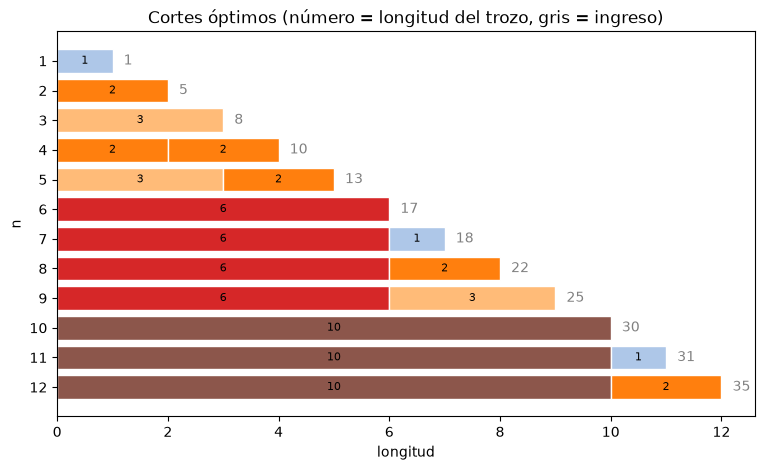

In [5]:
import matplotlib.pyplot as plt

p = precios + [31, 33]

fig, eje = plt.subplots(figsize=(9, 5))
colores = plt.cm.tab20.colors
for n in range(1, 13):
    valor, trozos = corte_varilla(n, p)
    inicio = 0
    for t in sorted(trozos, reverse=True):
        eje.barh(n, t, left=inicio, color=colores[t], edgecolor="white")
        eje.text(inicio + t / 2, n, t, ha="center", va="center", fontsize=8)
        inicio += t
    eje.text(n + 0.2, n, f"{valor}", va="center", color="gray")
eje.set(xlabel="longitud", ylabel="n", title="Cortes óptimos (número = longitud del trozo, gris = ingreso)")
eje.set_yticks(range(1, 13))
eje.invert_yaxis()
plt.show()